In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import sys

PROJECT_DIR = "/content/drive/MyDrive/simuteh"
NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebook")
SRC_DIR = os.path.join(PROJECT_DIR, "src")
DATA_DIR = os.path.join(PROJECT_DIR, "data", "sintetis")
HASIL_DIR = os.path.join(PROJECT_DIR, "hasil")

os.chdir(NOTEBOOK_DIR)

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

print("Lokasi proyek:", PROJECT_DIR)
print("Lokasi notebook:", os.getcwd())
print("Lokasi dataset:", DATA_DIR)
print("Lokasi hasil:", HASIL_DIR)

Lokasi proyek: /content/drive/MyDrive/simuteh
Lokasi notebook: /content/drive/MyDrive/simuteh/notebook
Lokasi dataset: /content/drive/MyDrive/simuteh/data/sintetis
Lokasi hasil: /content/drive/MyDrive/simuteh/hasil


In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca, tampil, kontras_bercak

label = pd.read_csv(os.path.join(DATA_DIR, "label.csv"))

print("OpenCV:", cv2.__version__)
print("Jumlah data:", len(label))
print("\nKolom dataset:")
print(label.columns.tolist())

print("\nDistribusi kelas:")
print(label["kelas"].value_counts())

print("\nDistribusi kondisi cahaya:")
print(label["kondisi_cahaya"].value_counts())

print("\nContoh data:")
display(label.head())

OpenCV: 4.14.0
Jumlah data: 60

Kolom dataset:
['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']

Distribusi kelas:
kelas
sehat     20
ringan    20
berat     20
Name: count, dtype: int64

Distribusi kondisi cahaya:
kondisi_cahaya
normal            12
gelap             12
terang            12
kontras_rendah    12
bayangan          12
Name: count, dtype: int64

Contoh data:


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0


In [4]:
# Warna dari PDF dalam format RGB
warna_bercak_rgb = np.uint8([[[196, 178, 86]]])
warna_daun_rgb = np.uint8([[[52, 136, 60]]])

# OpenCV menerima urutan BGR, sehingga data perlu dibalik
warna_bercak_bgr = warna_bercak_rgb[:, :, ::-1].copy()
warna_daun_bgr = warna_daun_rgb[:, :, ::-1].copy()

# Konversi ke keabuan
gray_bercak = cv2.cvtColor(
    warna_bercak_bgr, cv2.COLOR_BGR2GRAY
)[0, 0]

gray_daun = cv2.cvtColor(
    warna_daun_bgr, cv2.COLOR_BGR2GRAY
)[0, 0]

# Konversi ke HSV
hsv_bercak = cv2.cvtColor(
    warna_bercak_bgr, cv2.COLOR_BGR2HSV
)[0, 0]

hsv_daun = cv2.cvtColor(
    warna_daun_bgr, cv2.COLOR_BGR2HSV
)[0, 0]

print("Bercak")
print("Keabuan OpenCV:", int(gray_bercak))
print("H, S, V:", hsv_bercak.tolist())

print("\nDaun sehat")
print("Keabuan OpenCV:", int(gray_daun))
print("H, S, V:", hsv_daun.tolist())

print("\nSelisih intensitas keabuan:",
      abs(int(gray_bercak) - int(gray_daun)))

Bercak
Keabuan OpenCV: 173
H, S, V: [25, 143, 196]

Daun sehat
Keabuan OpenCV: 102
H, S, V: [63, 158, 136]

Selisih intensitas keabuan: 71


## Langkah 2.2. Rencana Akuisisi Citra

Rencana akuisisi citra disusun untuk memastikan bahwa foto daun teh memiliki kualitas yang memadai untuk membedakan bercak penyakit dari jaringan daun yang sehat. Pengambilan citra perlu memperhatikan jarak kamera, sudut pemotretan, resolusi, pencahayaan, dan konsistensi penamaan berkas.

Rencana ini juga mempertimbangkan hasil perhitungan geometri kamera pada Langkah 2.1. Perhitungan tersebut menunjukkan bahwa ukuran bercak dalam piksel dipengaruhi oleh jarak kamera dan resolusi citra. Oleh karena itu, jarak pemotretan perlu dijaga agar bercak kecil tetap terlihat setelah citra diubah ukurannya menjadi 640 × 480 piksel.

Pengambilan citra perlu mencakup kondisi pencahayaan yang beragam agar pemisahan bercak dan jaringan daun sehat dapat dievaluasi secara lebih menyeluruh. Pengelolaan data juga harus memperhatikan privasi, termasuk izin pengambilan gambar, penghapusan metadata EXIF sebelum citra dibagikan, dan larangan menyertakan wajah orang dalam citra.


### Tabel 1. Rencana Akuisisi Citra Daun Teh

| No. | Aspek                   | Rencana                                                                                                                                                      | Alasan                                                                                                                                                                    |
| --- | ----------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1   | Jarak kamera            | Sekitar 200 sampai 220 mm dari permukaan daun, dengan fokus yang baik dan jarak yang konsisten.                                                              | Berdasarkan perhitungan Langkah 2.1, jarak yang lebih dekat membantu mempertahankan ukuran bercak dalam piksel setelah citra diubah ukurannya.                            |
| 2   | Sudut pemotretan        | Kamera diarahkan tegak lurus terhadap permukaan daun. Usahakan penyimpangan sudut tidak lebih dari sekitar 15 derajat.                                       | Mengurangi perubahan bentuk bercak akibat perspektif dan menjaga konsistensi tampilan daun.                                                                               |
| 3   | Resolusi citra          | Gunakan citra asli beresolusi tinggi. Resolusi 4000 × 3000 piksel digunakan sebagai acuan perhitungan, kemudian citra diproses pada ukuran 640 × 480 piksel. | Resolusi asli yang memadai membantu mempertahankan detail bercak sebelum proses pengubahan ukuran.                                                                        |
| 4   | Referensi ukuran        | Letakkan penggaris atau objek berukuran diketahui di dekat daun, pada bidang yang sama, tanpa menutupi bagian daun yang diamati.                             | Membantu memperkirakan ukuran fisik bercak dan memeriksa skala citra.                                                                                                     |
| 5   | Kondisi pencahayaan     | Ambil atau evaluasi citra pada kondisi normal, gelap, terang, kontras rendah, dan bayangan.                                                                  | Perbedaan pencahayaan dapat memengaruhi warna dan kontras antara bercak dengan jaringan daun sehat.                                                                       |
| 6   | Jumlah citra per kelas  | Gunakan target seimbang, yaitu 20 citra untuk setiap kelas: sehat, bercak ringan, dan bercak berat.                                                          | Jumlah yang seimbang memudahkan perbandingan antarkelas. Target ini mengikuti pembagian data yang digunakan dalam praktikum, bukan ketentuan umum untuk semua penelitian. |
| 7   | Penamaan berkas         | Gunakan format konsisten, misalnya `teh_001.png`, `teh_002.png`, dan seterusnya. Simpan label kelas serta kondisi pencahayaan dalam tabel metadata.          | Memudahkan identifikasi, pemrosesan, dan pelacakan citra.                                                                                                                 |
| 8   | Izin pengambilan gambar | Dapatkan izin dari pemilik tanaman atau pihak yang bertanggung jawab sebelum mengambil gambar.                                                               | Memastikan pengambilan citra dilakukan dengan persetujuan pihak terkait.                                                                                                  |
| 9   | Metadata EXIF           | Periksa metadata EXIF dan hapus informasi yang berpotensi mengungkap lokasi atau informasi pribadi sebelum citra dibagikan secara publik.                    | Metadata foto dapat memuat informasi tambahan, termasuk koordinat lokasi jika tersedia.                                                                                   |
| 10  | Privasi visual          | Pastikan citra tidak memuat wajah orang atau informasi pribadi yang tidak diperlukan.                                                                        | Mengurangi risiko paparan informasi pribadi.                                                                                                                              |


In [5]:
# Langkah 2.3.1: Memeriksa struktur dataset

import os
import pandas as pd

LABEL_PATH = os.path.join(DATA_DIR, "label.csv")
CITRA_DIR = os.path.join(DATA_DIR, "citra")
MASK_DAUN_DIR = os.path.join(DATA_DIR, "mask_daun")
MASK_BERCAK_DIR = os.path.join(DATA_DIR, "mask_bercak")

# Membaca label dataset
label = pd.read_csv(LABEL_PATH)

print("Kolom pada label.csv:")
print(label.columns.tolist())

print("\nLima baris pertama:")
display(label.head())

print("\nContoh nama file citra:")
print(sorted(os.listdir(CITRA_DIR))[:10])

print("\nJumlah file citra:",
      len(os.listdir(CITRA_DIR)))

print("\nContoh file mask daun:")
print(sorted(os.listdir(MASK_DAUN_DIR))[:5])

print("\nContoh file mask bercak:")
print(sorted(os.listdir(MASK_BERCAK_DIR))[:5])

Kolom pada label.csv:
['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']

Lima baris pertama:


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0



Contoh nama file citra:
['teh_001.png', 'teh_002.png', 'teh_003.png', 'teh_004.png', 'teh_005.png', 'teh_006.png', 'teh_007.png', 'teh_008.png', 'teh_009.png', 'teh_010.png']

Jumlah file citra: 60

Contoh file mask daun:
['teh_001.png', 'teh_002.png', 'teh_003.png', 'teh_004.png', 'teh_005.png']

Contoh file mask bercak:
['teh_001.png', 'teh_002.png', 'teh_003.png', 'teh_004.png', 'teh_005.png']


Distribusi kelas:
kelas
sehat     20
ringan    20
berat     20
Name: count, dtype: int64

Distribusi kondisi pencahayaan:
kondisi_cahaya
normal            12
gelap             12
terang            12
kontras_rendah    12
bayangan          12
Name: count, dtype: int64


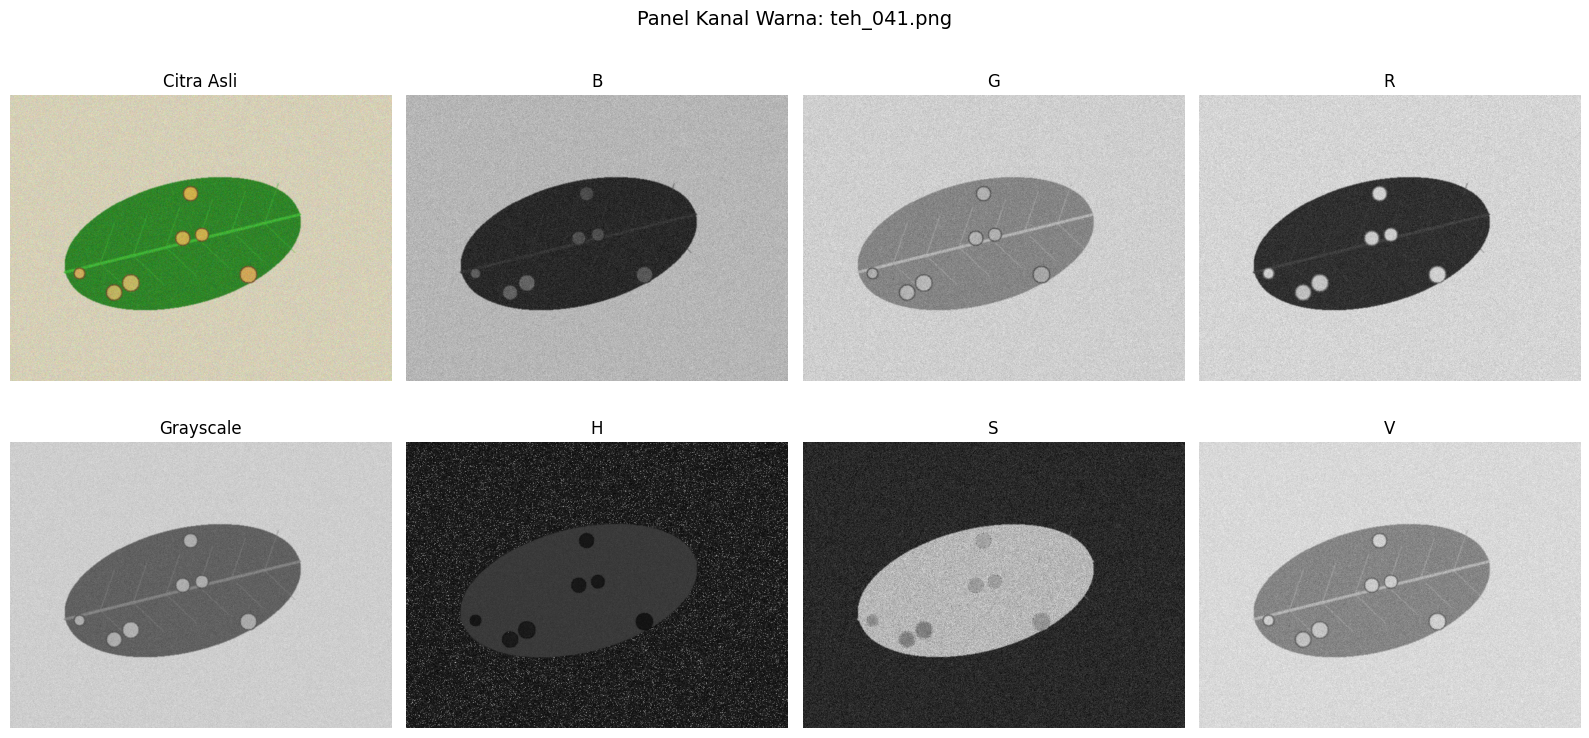

Nama citra: teh_041.png
Ukuran citra: (480, 640, 3)


In [8]:
# Langkah 2.3.2: Panel delapan tampilan citra dan perhitungan KB

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tampilkan kelas yang tersedia
print("Distribusi kelas:")
print(label["kelas"].value_counts())

print("\nDistribusi kondisi pencahayaan:")
print(label["kondisi_cahaya"].value_counts())

# Cari citra dengan bercak berat
kelas_berat = label[
    label["kelas"].astype(str).str.lower().isin(
        ["bercak_berat", "bercak berat", "berat", "heavy"]
    )
]

if kelas_berat.empty:
    raise ValueError(
        "Kelas bercak berat tidak ditemukan. "
        "Periksa nama kelas yang tercetak di atas."
    )

# Ambil citra bercak berat pertama
nama_file = kelas_berat.iloc[0]["nama_file"]
path_citra = os.path.join(CITRA_DIR, nama_file)
path_mask_daun = os.path.join(MASK_DAUN_DIR, nama_file)
path_mask_bercak = os.path.join(MASK_BERCAK_DIR, nama_file)

# Baca citra dan mask
citra_bgr = cv2.imread(path_citra)
mask_daun = cv2.imread(path_mask_daun, cv2.IMREAD_GRAYSCALE)
mask_bercak = cv2.imread(path_mask_bercak, cv2.IMREAD_GRAYSCALE)

if citra_bgr is None:
    raise FileNotFoundError(f"Citra tidak ditemukan: {path_citra}")

if mask_daun is None or mask_bercak is None:
    raise FileNotFoundError(
        "Mask daun atau mask bercak tidak ditemukan."
    )

# Pastikan ukuran mask sesuai dengan citra
if mask_daun.shape != citra_bgr.shape[:2]:
    raise ValueError("Ukuran mask daun berbeda dari ukuran citra.")

if mask_bercak.shape != citra_bgr.shape[:2]:
    raise ValueError("Ukuran mask bercak berbeda dari ukuran citra.")

# Konversi kanal warna
citra_rgb = cv2.cvtColor(citra_bgr, cv2.COLOR_BGR2RGB)
citra_gray = cv2.cvtColor(citra_bgr, cv2.COLOR_BGR2GRAY)
citra_hsv = cv2.cvtColor(citra_bgr, cv2.COLOR_BGR2HSV)

kanal = {
    "Citra Asli": citra_rgb,
    "B": citra_bgr[:, :, 0],
    "G": citra_bgr[:, :, 1],
    "R": citra_bgr[:, :, 2],
    "Grayscale": citra_gray,
    "H": citra_hsv[:, :, 0],
    "S": citra_hsv[:, :, 1],
    "V": citra_hsv[:, :, 2],
}

# Tampilkan panel delapan tampilan
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (nama_kanal, gambar) in zip(axes.flat, kanal.items()):
    if nama_kanal == "Citra Asli":
        ax.imshow(gambar)
    else:
        ax.imshow(gambar, cmap="gray", vmin=0, vmax=255)

    ax.set_title(nama_kanal)
    ax.axis("off")

plt.suptitle(f"Panel Kanal Warna: {nama_file}", fontsize=14)
plt.tight_layout()
plt.show()

print("Nama citra:", nama_file)
print("Ukuran citra:", citra_bgr.shape)


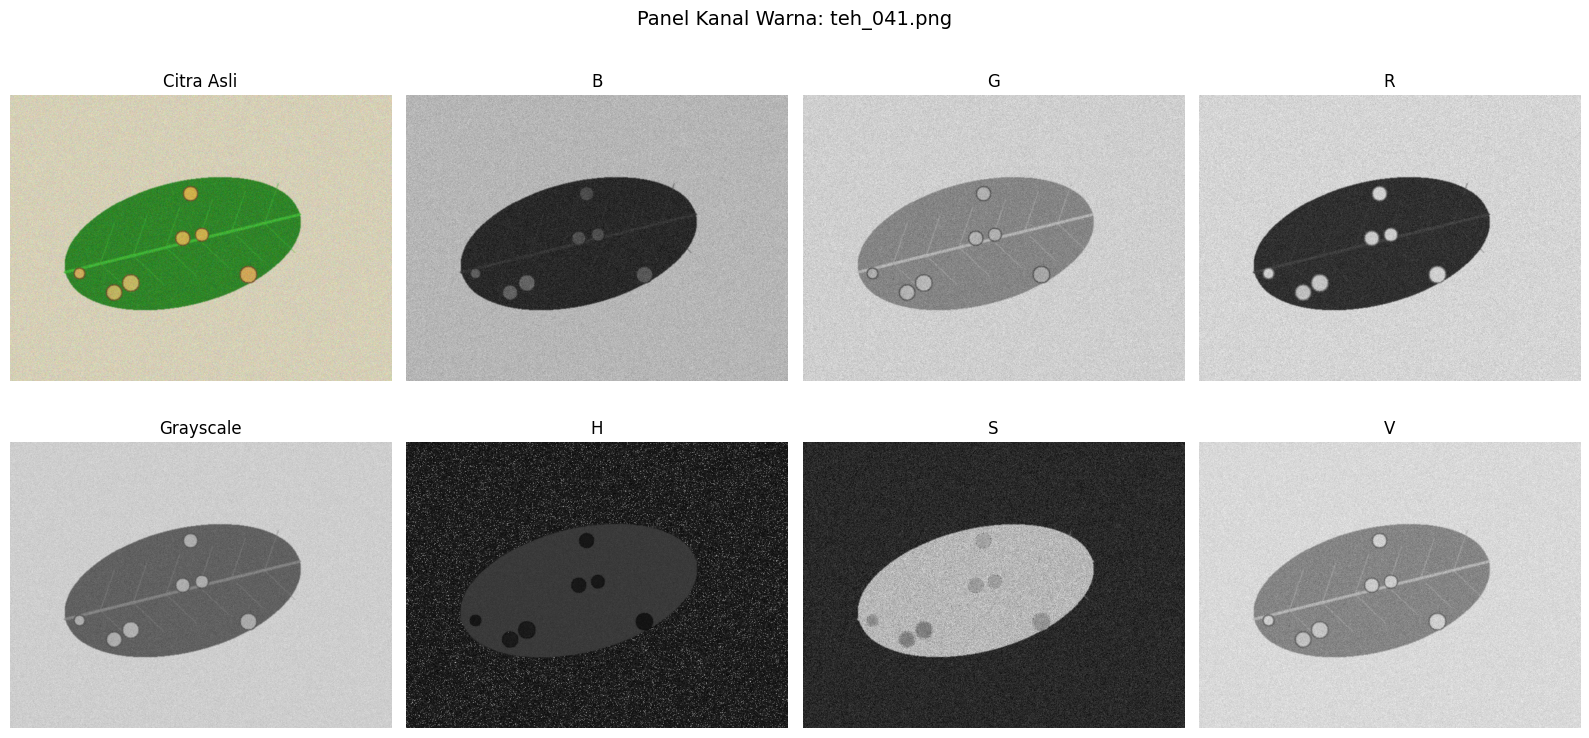

Panel tersimpan di: /content/drive/MyDrive/simuteh/hasil/b2_panel_kanal_warna.png


In [9]:
# Simpan panel kanal warna untuk dokumentasi praktikum

os.makedirs(HASIL_DIR, exist_ok=True)

nama_output = os.path.join(HASIL_DIR, "b2_panel_kanal_warna.png")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (nama_kanal, gambar) in zip(axes.flat, kanal.items()):
    if nama_kanal == "Citra Asli":
        ax.imshow(gambar)
    else:
        ax.imshow(gambar, cmap="gray", vmin=0, vmax=255)

    ax.set_title(nama_kanal)
    ax.axis("off")

plt.suptitle(f"Panel Kanal Warna: {nama_file}", fontsize=14)
plt.tight_layout()
plt.savefig(nama_output, dpi=150, bbox_inches="tight")
plt.show()

print("Panel tersimpan di:", nama_output)

In [10]:
# Langkah 2.3.3: Menghitung Kontras Bercak (KB)

# Pastikan mask menggunakan nilai biner
mask_daun_bin = mask_daun > 0
mask_bercak_bin = mask_bercak > 0

# Area daun sehat adalah bagian daun yang bukan bercak
mask_sehat_bin = mask_daun_bin & (~mask_bercak_bin)

# Periksa jumlah piksel pada masing-masing area
jumlah_piksel_bercak = np.count_nonzero(
    mask_bercak_bin & mask_daun_bin
)

jumlah_piksel_sehat = np.count_nonzero(mask_sehat_bin)

print("Citra:", nama_file)
print("Piksel bercak:", jumlah_piksel_bercak)
print("Piksel daun sehat:", jumlah_piksel_sehat)

if jumlah_piksel_bercak == 0:
    raise ValueError(
        "Mask bercak tidak memiliki piksel di dalam area daun."
    )

if jumlah_piksel_sehat == 0:
    raise ValueError(
        "Mask daun sehat tidak memiliki piksel."
    )

# Kanal yang akan dievaluasi
kanal_uji = {
    "B": citra_bgr[:, :, 0],
    "G": citra_bgr[:, :, 1],
    "R": citra_bgr[:, :, 2],
    "Grayscale": citra_gray,
    "H": citra_hsv[:, :, 0],
    "S": citra_hsv[:, :, 1],
    "V": citra_hsv[:, :, 2],
}

hasil_kb = []

for nama_kanal, gambar in kanal_uji.items():

    # Ambil intensitas piksel pada area bercak dan daun sehat
    nilai_bercak = gambar[
        mask_bercak_bin & mask_daun_bin
    ].astype(np.float64)

    nilai_sehat = gambar[
        mask_sehat_bin
    ].astype(np.float64)

    # Hitung rata-rata dan simpangan baku daun sehat
    mean_bercak = np.mean(nilai_bercak)
    mean_sehat = np.mean(nilai_sehat)
    std_sehat = np.std(nilai_sehat)

    # Hitung KB sesuai rumus praktikum
    if std_sehat == 0:
        kb = np.nan
    else:
        kb = abs(mean_bercak - mean_sehat) / std_sehat

    hasil_kb.append({
        "kanal": nama_kanal,
        "mean_bercak": mean_bercak,
        "mean_sehat": mean_sehat,
        "std_sehat": std_sehat,
        "KB": kb
    })

tabel_kb = pd.DataFrame(hasil_kb)

print("\nHasil perhitungan KB:")
display(tabel_kb.round(4))

Citra: teh_041.png
Piksel bercak: 3836
Piksel daun sehat: 61888

Hasil perhitungan KB:


,kanal,mean_bercak,mean_sehat,std_sehat,KB
0,B,74.4333,41.6311,12.1600,2.6975
1,G,151.4818,134.4368,13.5638,1.2567
2,R,172.9591,48.9107,12.7435,9.7342
3,Grayscale,149.1199,98.2854,9.7828,5.1963
4,H,24.1799,57.8002,4.8173,6.9791
5,S,146.6697,181.8935,20.3941,1.7272
6,V,174.8123,134.4368,13.5638,2.9767


In [11]:
# Simpan hasil KB untuk citra teh_041.png

os.makedirs(HASIL_DIR, exist_ok=True)

path_kb = os.path.join(
    HASIL_DIR,
    "b2_kb_teh_041.csv"
)

tabel_kb.to_csv(path_kb, index=False)

print("Hasil KB tersimpan di:", path_kb)

Hasil KB tersimpan di: /content/drive/MyDrive/simuteh/hasil/b2_kb_teh_041.csv


## Langkah 2.4. Eksperimen Sampling dan Kuantisasi

Eksperimen sampling dan kuantisasi dilakukan untuk mengamati perubahan kualitas visual citra daun teh ketika resolusi dan jumlah tingkat intensitas dikurangi. Pengamatan difokuskan pada kemampuan citra mempertahankan detail bercak penyakit.

Pada eksperimen sampling, ukuran citra diperkecil menggunakan beberapa faktor skala. Pada eksperimen kuantisasi, jumlah tingkat intensitas dikurangi untuk mengamati perubahan detail dan kontras bercak. Hasil setiap percobaan dibandingkan dengan citra asli.


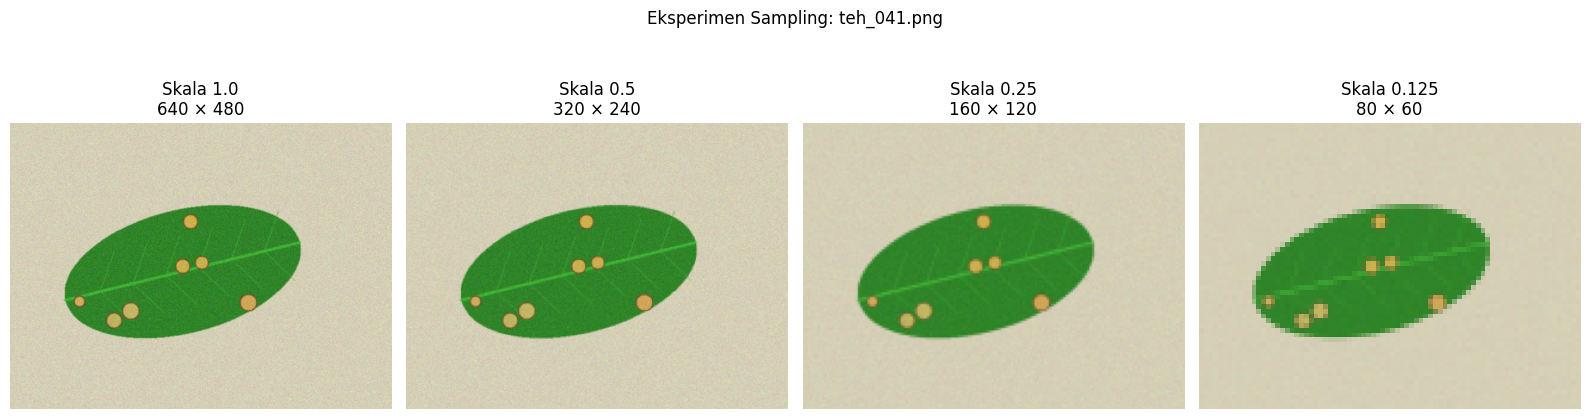

In [12]:
# Langkah 2.4.1: Eksperimen sampling

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Gunakan citra yang sama dengan eksperimen sebelumnya
citra_asli = citra_rgb.copy()

# Faktor skala untuk sampling
faktor_sampling = [1.0, 0.5, 0.25, 0.125]

hasil_sampling = []

for faktor in faktor_sampling:
    lebar_baru = max(1, int(citra_asli.shape[1] * faktor))
    tinggi_baru = max(1, int(citra_asli.shape[0] * faktor))

    # Perkecil citra
    citra_kecil = cv2.resize(
        citra_asli,
        (lebar_baru, tinggi_baru),
        interpolation=cv2.INTER_AREA
    )

    hasil_sampling.append(
        (faktor, citra_kecil, lebar_baru, tinggi_baru)
    )

# Tampilkan hasil sampling
fig, axes = plt.subplots(1, len(hasil_sampling), figsize=(16, 5))

for ax, (faktor, gambar, lebar, tinggi) in zip(
    axes, hasil_sampling
):
    ax.imshow(gambar)
    ax.set_title(
        f"Skala {faktor}\n{lebar} × {tinggi}"
    )
    ax.axis("off")

plt.suptitle(f"Eksperimen Sampling: {nama_file}")
plt.tight_layout()
plt.show()

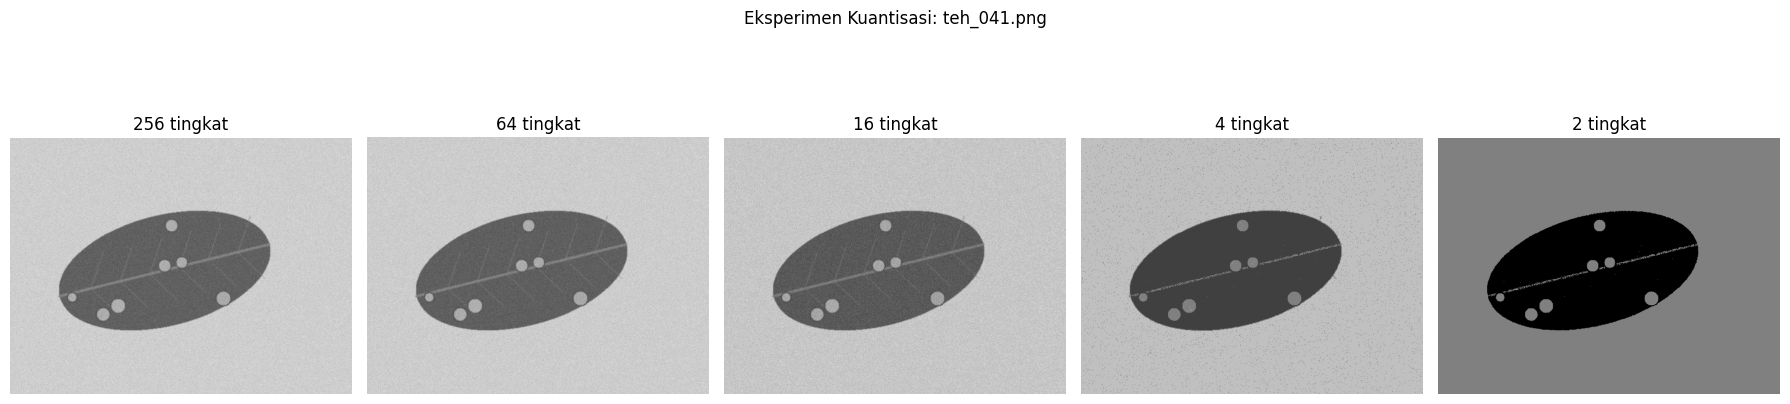

In [13]:
# Langkah 2.4.2: Eksperimen kuantisasi

# Konversi citra asli ke grayscale
gray_asli = cv2.cvtColor(
    citra_bgr,
    cv2.COLOR_BGR2GRAY
)

# Jumlah tingkat intensitas yang diuji
jumlah_tingkat = [256, 64, 16, 4, 2]

hasil_kuantisasi = []

for tingkat in jumlah_tingkat:
    # Jarak antarlevel intensitas
    langkah = 256 / tingkat

    # Kuantisasi dan kembalikan nilai ke rentang 0-255
    citra_quant = (
        np.floor(gray_asli.astype(np.float32) / langkah)
        * langkah
    )

    citra_quant = np.clip(
        citra_quant, 0, 255
    ).astype(np.uint8)

    hasil_kuantisasi.append((tingkat, citra_quant))

# Tampilkan hasil kuantisasi
fig, axes = plt.subplots(1, len(hasil_kuantisasi), figsize=(18, 5))

for ax, (tingkat, gambar) in zip(
    axes, hasil_kuantisasi
):
    ax.imshow(gambar, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{tingkat} tingkat")
    ax.axis("off")

plt.suptitle(f"Eksperimen Kuantisasi: {nama_file}")
plt.tight_layout()
plt.show()

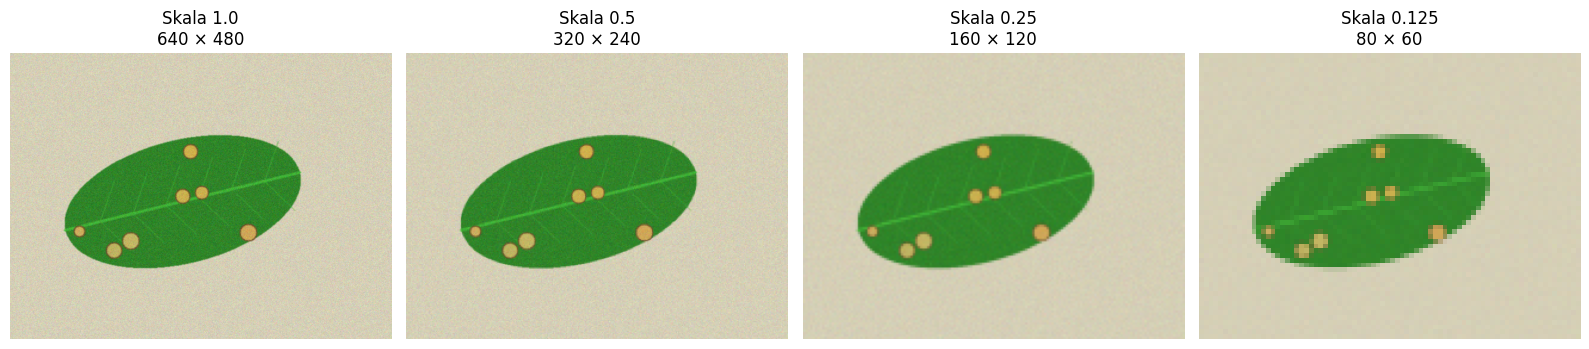

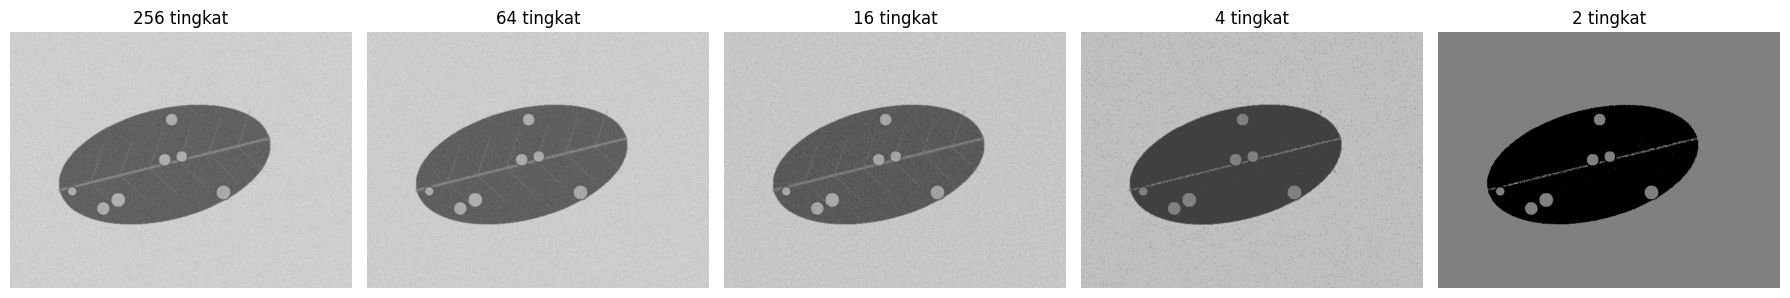

Hasil sampling: /content/drive/MyDrive/simuteh/hasil/b2_eksperimen_sampling.png
Hasil kuantisasi: /content/drive/MyDrive/simuteh/hasil/b2_eksperimen_kuantisasi.png


In [14]:
# Simpan hasil eksperimen sampling

path_sampling = os.path.join(
    HASIL_DIR,
    "b2_eksperimen_sampling.png"
)

fig, axes = plt.subplots(1, len(hasil_sampling), figsize=(16, 5))

for ax, (faktor, gambar, lebar, tinggi) in zip(
    axes, hasil_sampling
):
    ax.imshow(gambar)
    ax.set_title(f"Skala {faktor}\n{lebar} × {tinggi}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(path_sampling, dpi=150, bbox_inches="tight")
plt.show()

# Simpan hasil eksperimen kuantisasi

path_kuantisasi = os.path.join(
    HASIL_DIR,
    "b2_eksperimen_kuantisasi.png"
)

fig, axes = plt.subplots(
    1, len(hasil_kuantisasi), figsize=(18, 5)
)

for ax, (tingkat, gambar) in zip(
    axes, hasil_kuantisasi
):
    ax.imshow(gambar, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{tingkat} tingkat")
    ax.axis("off")

plt.tight_layout()
plt.savefig(path_kuantisasi, dpi=150, bbox_inches="tight")
plt.show()

print("Hasil sampling:", path_sampling)
print("Hasil kuantisasi:", path_kuantisasi)

In [15]:
# Langkah 2.5.1: Menghitung KB untuk seluruh citra kelas berat

import os
import cv2
import numpy as np
import pandas as pd

# Membaca kembali label dataset
label = pd.read_csv(
    os.path.join(DATA_DIR, "label.csv")
)

# Memilih 20 citra kelas berat
data_berat = label[
    label["kelas"].astype(str).str.lower() == "berat"
].copy()

print("Jumlah citra kelas berat:", len(data_berat))

if len(data_berat) != 20:
    raise ValueError(
        f"Seharusnya ada 20 citra kelas berat, "
        f"tetapi ditemukan {len(data_berat)}."
    )

# Daftar kanal yang akan dihitung
nama_kanal = [
    "B", "G", "R", "Grayscale", "H", "S", "V"
]

hasil_semua = []

for _, baris in data_berat.iterrows():

    nama_file = baris["nama_file"]
    kondisi = baris["kondisi_cahaya"]

    path_citra = os.path.join(CITRA_DIR, nama_file)
    path_mask_daun = os.path.join(MASK_DAUN_DIR, nama_file)
    path_mask_bercak = os.path.join(MASK_BERCAK_DIR, nama_file)

    # Membaca citra dan mask
    citra = cv2.imread(path_citra)
    mask_daun = cv2.imread(
        path_mask_daun, cv2.IMREAD_GRAYSCALE
    )
    mask_bercak = cv2.imread(
        path_mask_bercak, cv2.IMREAD_GRAYSCALE
    )

    if citra is None or mask_daun is None or mask_bercak is None:
        raise FileNotFoundError(
            f"Citra atau mask tidak ditemukan untuk {nama_file}"
        )

    # Membuat area daun sehat dan bercak
    area_daun = mask_daun > 0
    area_bercak = (mask_bercak > 0) & area_daun
    area_sehat = area_daun & (~area_bercak)

    if np.count_nonzero(area_bercak) == 0:
        raise ValueError(
            f"Mask bercak kosong untuk {nama_file}"
        )

    if np.count_nonzero(area_sehat) == 0:
        raise ValueError(
            f"Mask daun sehat kosong untuk {nama_file}"
        )

    # Membuat kanal warna
    gray = cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(citra, cv2.COLOR_BGR2HSV)

    kanal = {
        "B": citra[:, :, 0],
        "G": citra[:, :, 1],
        "R": citra[:, :, 2],
        "Grayscale": gray,
        "H": hsv[:, :, 0],
        "S": hsv[:, :, 1],
        "V": hsv[:, :, 2]
    }

    # Menghitung KB untuk setiap kanal
    for nama, gambar in kanal.items():

        nilai_bercak = gambar[area_bercak].astype(np.float64)
        nilai_sehat = gambar[area_sehat].astype(np.float64)

        mean_bercak = np.mean(nilai_bercak)
        mean_sehat = np.mean(nilai_sehat)
        std_sehat = np.std(nilai_sehat)

        kb = (
            abs(mean_bercak - mean_sehat) / std_sehat
            if std_sehat > 0 else np.nan
        )

        hasil_semua.append({
            "nama_file": nama_file,
            "kelas": baris["kelas"],
            "kondisi_cahaya": kondisi,
            "kanal": nama,
            "mean_bercak": mean_bercak,
            "mean_sehat": mean_sehat,
            "std_sehat": std_sehat,
            "KB": kb
        })

# Membuat tabel hasil
df_kb_berat = pd.DataFrame(hasil_semua)

print("Jumlah baris hasil:", len(df_kb_berat))
display(df_kb_berat.head(14).round(4))

Jumlah citra kelas berat: 20
Jumlah baris hasil: 140


,nama_file,kelas,kondisi_cahaya,kanal,mean_bercak,mean_sehat,std_sehat,KB
0,teh_041.png,berat,normal,B,74.4333,41.6311,12.1600,2.6975
1,teh_041.png,berat,normal,G,151.4818,134.4368,13.5638,1.2567
2,teh_041.png,berat,normal,R,172.9591,48.9107,12.7435,9.7342
3,teh_041.png,berat,normal,Grayscale,149.1199,98.2854,9.7828,5.1963
4,teh_041.png,berat,normal,H,24.1799,57.8002,4.8173,6.9791
5,teh_041.png,berat,normal,S,146.6697,181.8935,20.3941,1.7272
6,teh_041.png,berat,normal,V,174.8123,134.4368,13.5638,2.9767
7,teh_042.png,berat,gelap,B,20.3089,8.9469,7.2773,1.5613
8,teh_042.png,berat,gelap,G,98.0120,71.1021,12.3779,2.1740
9,teh_042.png,berat,gelap,R,118.3555,20.8193,8.7419,11.1573


In [16]:
# Langkah 2.5.2: Rata-rata KB berdasarkan kanal dan pencahayaan

tabel_rata_berat = (
    df_kb_berat
    .groupby(["kondisi_cahaya", "kanal"], as_index=False)
    .agg(
        rata_rata_KB=("KB", "mean"),
        jumlah_citra=("nama_file", "nunique")
    )
)

# Urutan kondisi pencahayaan
urutan_cahaya = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

tabel_rata_berat["kondisi_cahaya"] = pd.Categorical(
    tabel_rata_berat["kondisi_cahaya"],
    categories=urutan_cahaya,
    ordered=True
)

tabel_rata_berat = tabel_rata_berat.sort_values(
    ["kondisi_cahaya", "kanal"]
)

print("Rata-rata KB kelas berat berdasarkan pencahayaan:")
display(tabel_rata_berat.round(4))

Rata-rata KB kelas berat berdasarkan pencahayaan:


,kondisi_cahaya,kanal,rata_rata_KB,jumlah_citra
21,normal,B,2.4489,4
22,normal,G,1.8822,4
23,normal,Grayscale,5.6666,4
24,normal,H,7.3885,4
25,normal,R,10.7108,4
26,normal,S,1.1030,4
27,normal,V,3.5041,4
7,gelap,B,1.5427,4
8,gelap,G,1.1252,4
9,gelap,Grayscale,4.2044,4


In [17]:
# Langkah 2.5.3: Menyimpan hasil KB kelas berat

os.makedirs(HASIL_DIR, exist_ok=True)

path_csv_berat = os.path.join(
    HASIL_DIR,
    "b2_kb_kanal.csv"
)

df_kb_berat.to_csv(
    path_csv_berat,
    index=False
)

print("File berhasil disimpan:", path_csv_berat)
print("Jumlah baris:", len(df_kb_berat))

File berhasil disimpan: /content/drive/MyDrive/simuteh/hasil/b2_kb_kanal.csv
Jumlah baris: 140


In [18]:
# Membuat Tabel 8: Rata-rata KB kelas berat berdasarkan pencahayaan

tabel8_berat = tabel_rata_berat.pivot(
    index="kondisi_cahaya",
    columns="kanal",
    values="rata_rata_KB"
)

urutan_kanal = [
    "B", "G", "R", "Grayscale", "H", "S", "V"
]

tabel8_berat = tabel8_berat.reindex(
    columns=urutan_kanal
)

urutan_cahaya = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

tabel8_berat = tabel8_berat.reindex(urutan_cahaya)

print("Tabel 8. Rata-rata KB kelas berat berdasarkan kondisi pencahayaan")
display(tabel8_berat.round(4))

Tabel 8. Rata-rata KB kelas berat berdasarkan kondisi pencahayaan


kanal,B,G,R,Grayscale,H,S,V
kondisi_cahaya,,,,,,,
normal,2.4489,1.8822,10.7108,5.6666,7.3885,1.1030,3.5041
gelap,1.5427,1.1252,9.9218,4.2044,6.1431,0.9906,2.8585
terang,1.7601,0.2749,8.1380,3.6542,7.2889,0.9888,1.6045
kontras_rendah,0.8835,0.4252,4.1342,2.1824,2.3564,0.2408,1.4412
bayangan,0.9141,0.4788,5.2400,1.5571,4.9399,0.4418,1.0022


In [19]:
# Langkah 2.6.1: Menghitung KB untuk seluruh citra kelas ringan

data_ringan = label[
    label["kelas"].astype(str).str.lower() == "ringan"
].copy()

print("Jumlah citra kelas ringan:", len(data_ringan))

if len(data_ringan) != 20:
    raise ValueError(
        f"Seharusnya ada 20 citra kelas ringan, "
        f"tetapi ditemukan {len(data_ringan)}."
    )

hasil_ringan = []

for _, baris in data_ringan.iterrows():

    nama_file = baris["nama_file"]
    kondisi = baris["kondisi_cahaya"]

    citra_path = os.path.join(CITRA_DIR, nama_file)
    daun_path = os.path.join(MASK_DAUN_DIR, nama_file)
    bercak_path = os.path.join(MASK_BERCAK_DIR, nama_file)

    citra = cv2.imread(citra_path)
    mask_daun = cv2.imread(
        daun_path, cv2.IMREAD_GRAYSCALE
    )
    mask_bercak = cv2.imread(
        bercak_path, cv2.IMREAD_GRAYSCALE
    )

    if citra is None or mask_daun is None or mask_bercak is None:
        raise FileNotFoundError(
            f"Citra atau mask tidak ditemukan: {nama_file}"
        )

    area_daun = mask_daun > 0
    area_bercak = (mask_bercak > 0) & area_daun
    area_sehat = area_daun & (~area_bercak)

    if np.count_nonzero(area_bercak) == 0:
        raise ValueError(
            f"Mask bercak kosong untuk {nama_file}"
        )

    if np.count_nonzero(area_sehat) == 0:
        raise ValueError(
            f"Mask daun sehat kosong untuk {nama_file}"
        )

    gray = cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(citra, cv2.COLOR_BGR2HSV)

    kanal = {
        "B": citra[:, :, 0],
        "G": citra[:, :, 1],
        "R": citra[:, :, 2],
        "Grayscale": gray,
        "H": hsv[:, :, 0],
        "S": hsv[:, :, 1],
        "V": hsv[:, :, 2]
    }

    for nama_kanal, gambar in kanal.items():

        nilai_bercak = gambar[area_bercak].astype(np.float64)
        nilai_sehat = gambar[area_sehat].astype(np.float64)

        mean_bercak = np.mean(nilai_bercak)
        mean_sehat = np.mean(nilai_sehat)
        std_sehat = np.std(nilai_sehat)

        kb = (
            abs(mean_bercak - mean_sehat) / std_sehat
            if std_sehat > 0 else np.nan
        )

        hasil_ringan.append({
            "nama_file": nama_file,
            "kelas": baris["kelas"],
            "kondisi_cahaya": kondisi,
            "kanal": nama_kanal,
            "mean_bercak": mean_bercak,
            "mean_sehat": mean_sehat,
            "std_sehat": std_sehat,
            "KB": kb
        })

df_kb_ringan = pd.DataFrame(hasil_ringan)

print("Jumlah baris hasil:", len(df_kb_ringan))
display(df_kb_ringan.head(14).round(4))

Jumlah citra kelas ringan: 20
Jumlah baris hasil: 140


,nama_file,kelas,kondisi_cahaya,kanal,mean_bercak,mean_sehat,std_sehat,KB
0,teh_021.png,ringan,normal,B,66.1423,51.6706,12.7649,1.1337
1,teh_021.png,ringan,normal,G,137.3281,124.3260,13.7238,0.9474
2,teh_021.png,ringan,normal,R,156.9802,62.7767,12.9054,7.2996
3,teh_021.png,ringan,normal,Grayscale,135.0830,97.6410,9.9092,3.7785
4,teh_021.png,ringan,normal,H,23.8972,55.7385,6.4969,4.9010
5,teh_021.png,ringan,normal,S,148.6680,153.3238,24.2669,0.1919
6,teh_021.png,ringan,normal,V,158.7036,124.3267,13.7231,2.5050
7,teh_022.png,ringan,gelap,B,20.2648,8.8794,7.1142,1.6004
8,teh_022.png,ringan,gelap,G,79.5494,73.3365,12.0780,0.5144
9,teh_022.png,ringan,gelap,R,104.4901,14.8946,8.0494,11.1307


In [20]:
# Langkah 2.6.2: Rata-rata KB kelas ringan berdasarkan pencahayaan

tabel_rata_ringan = (
    df_kb_ringan
    .groupby(["kondisi_cahaya", "kanal"], as_index=False)
    .agg(
        rata_rata_KB=("KB", "mean"),
        jumlah_citra=("nama_file", "nunique")
    )
)

tabel_rata_ringan["kondisi_cahaya"] = pd.Categorical(
    tabel_rata_ringan["kondisi_cahaya"],
    categories=[
        "normal",
        "gelap",
        "terang",
        "kontras_rendah",
        "bayangan"
    ],
    ordered=True
)

tabel_rata_ringan = tabel_rata_ringan.sort_values(
    ["kondisi_cahaya", "kanal"]
)

print("Rata-rata KB kelas ringan:")
display(tabel_rata_ringan.round(4))

Rata-rata KB kelas ringan:


,kondisi_cahaya,kanal,rata_rata_KB,jumlah_citra
21,normal,B,1.6409,4
22,normal,G,0.6178,4
23,normal,Grayscale,4.0125,4
24,normal,H,8.3002,4
25,normal,R,9.6467,4
26,normal,S,1.0954,4
27,normal,V,2.1318,4
7,gelap,B,0.7746,4
8,gelap,G,0.7314,4
9,gelap,Grayscale,2.5948,4


In [21]:
# Menyimpan hasil perhitungan kelas ringan

path_csv_ringan = os.path.join(
    HASIL_DIR,
    "b2_kb_ringan.csv"
)

df_kb_ringan.to_csv(path_csv_ringan, index=False)

print("Hasil kelas ringan tersimpan:", path_csv_ringan)
print("Jumlah baris:", len(df_kb_ringan))

Hasil kelas ringan tersimpan: /content/drive/MyDrive/simuteh/hasil/b2_kb_ringan.csv
Jumlah baris: 140


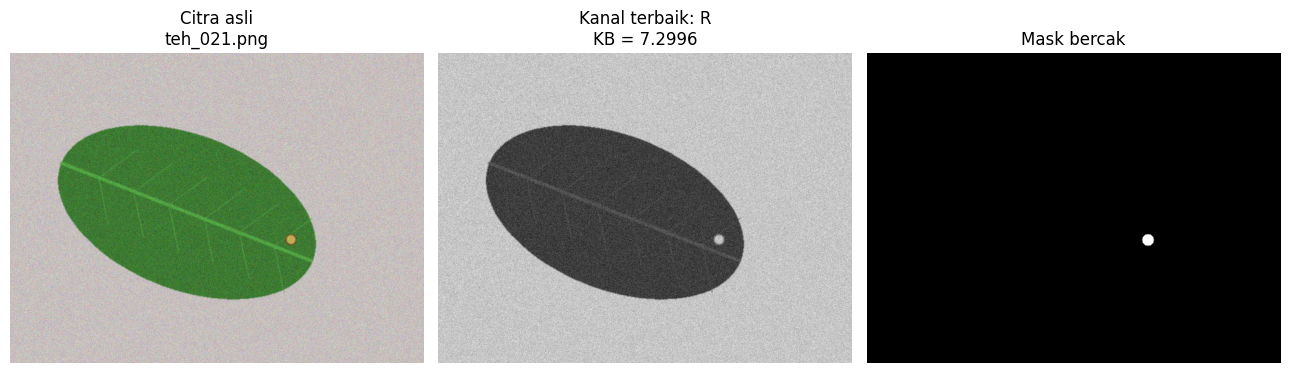

File: teh_021.png
Kanal terbaik: R
Nilai KB: 7.2996




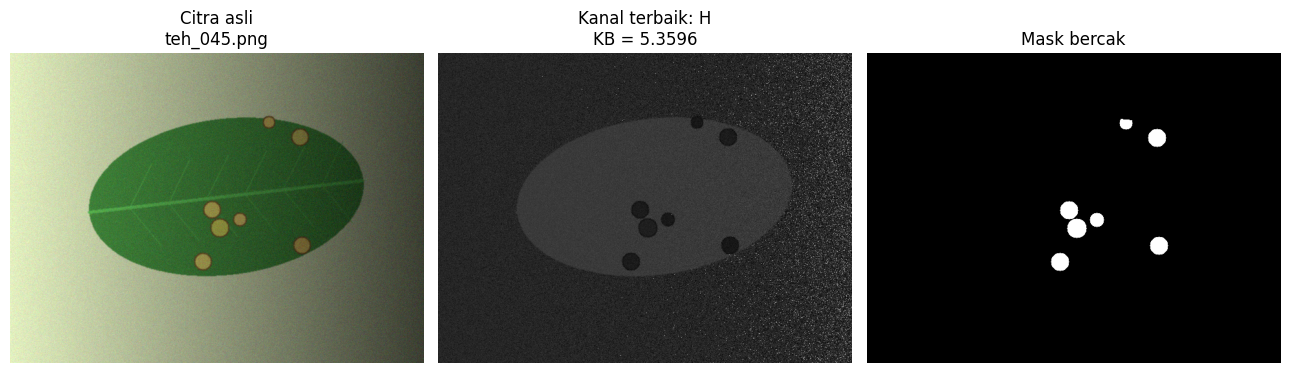

File: teh_045.png
Kanal terbaik: H
Nilai KB: 5.3596


In [22]:
# Langkah 2.6.3: Visualisasi kanal terbaik teh_021 dan teh_045

def tampilkan_kanal_terbaik(nama_file, tabel_kb):
    # Cari hasil KB untuk citra yang dipilih
    hasil_citra = tabel_kb[
        tabel_kb["nama_file"] == nama_file
    ].copy()

    if hasil_citra.empty:
        raise ValueError(
            f"Hasil KB untuk {nama_file} tidak ditemukan."
        )

    # Pilih kanal dengan KB tertinggi
    hasil_citra = hasil_citra.dropna(subset=["KB"])
    baris_terbaik = hasil_citra.loc[
        hasil_citra["KB"].idxmax()
    ]

    nama_kanal = baris_terbaik["kanal"]
    nilai_kb = baris_terbaik["KB"]

    # Baca citra dan mask
    path_citra = os.path.join(CITRA_DIR, nama_file)
    path_mask = os.path.join(MASK_BERCAK_DIR, nama_file)

    citra = cv2.imread(path_citra)
    mask = cv2.imread(path_mask, cv2.IMREAD_GRAYSCALE)

    if citra is None or mask is None:
        raise FileNotFoundError(
            f"Citra atau mask tidak ditemukan untuk {nama_file}"
        )

    gray = cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(citra, cv2.COLOR_BGR2HSV)

    kanal = {
        "B": citra[:, :, 0],
        "G": citra[:, :, 1],
        "R": citra[:, :, 2],
        "Grayscale": gray,
        "H": hsv[:, :, 0],
        "S": hsv[:, :, 1],
        "V": hsv[:, :, 2]
    }

    # Tampilkan citra asli, kanal terbaik, dan mask bercak
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    axes[0].imshow(cv2.cvtColor(citra, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Citra asli\n{nama_file}")

    axes[1].imshow(
        kanal[nama_kanal],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1].set_title(
        f"Kanal terbaik: {nama_kanal}\nKB = {nilai_kb:.4f}"
    )

    axes[2].imshow(mask, cmap="gray")
    axes[2].set_title("Mask bercak")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"File: {nama_file}")
    print(f"Kanal terbaik: {nama_kanal}")
    print(f"Nilai KB: {nilai_kb:.4f}")

    return nama_kanal, nilai_kb


# Citra ringan, pencahayaan normal
kanal_021, kb_021 = tampilkan_kanal_terbaik(
    "teh_021.png",
    df_kb_ringan
)

print("\n" + "=" * 40 + "\n")

# Citra berat, pencahayaan bayangan
kanal_045, kb_045 = tampilkan_kanal_terbaik(
    "teh_045.png",
    df_kb_berat
)

In [23]:
# Langkah 2.6.4: Menyimpan hasil dan membuat tabel perbandingan

# Simpan hasil lengkap kelas ringan
path_ringan = os.path.join(
    HASIL_DIR,
    "b2_kb_ringan.csv"
)

df_kb_ringan.to_csv(path_ringan, index=False)

# Rata-rata KB kelas berat dan ringan per kanal
rata_berat_kanal = (
    df_kb_berat
    .groupby("kanal")["KB"]
    .mean()
    .rename("rata_rata_KB_berat")
)

rata_ringan_kanal = (
    df_kb_ringan
    .groupby("kanal")["KB"]
    .mean()
    .rename("rata_rata_KB_ringan")
)

tabel_perbandingan = pd.concat(
    [rata_berat_kanal, rata_ringan_kanal],
    axis=1
).reset_index()

print("Perbandingan rata-rata KB kelas berat dan ringan:")
display(tabel_perbandingan.round(4))

# Simpan tabel perbandingan
path_perbandingan = os.path.join(
    HASIL_DIR,
    "b2_perbandingan_kb.csv"
)

tabel_perbandingan.to_csv(
    path_perbandingan,
    index=False
)

print("\nFile tersimpan:")
print(path_ringan)
print(path_perbandingan)

Perbandingan rata-rata KB kelas berat dan ringan:


,kanal,rata_rata_KB_berat,rata_rata_KB_ringan
0,B,1.5099,0.9820
1,G,0.8373,0.6111
2,Grayscale,3.4529,2.2568
3,H,5.6234,5.5979
4,R,7.6290,6.3386
5,S,0.7530,0.8745
6,V,2.0821,1.0997



File tersimpan:
/content/drive/MyDrive/simuteh/hasil/b2_kb_ringan.csv
/content/drive/MyDrive/simuteh/hasil/b2_perbandingan_kb.csv


In [24]:
# Gabungkan rata-rata KB kelas ringan dan berat
perbandingan_kb = pd.concat([
    tabel_rata_ringan.assign(kelas="ringan"),
    tabel_rata_berat.assign(kelas="berat")
], ignore_index=True)

# Tampilkan hasil
display(perbandingan_kb)

# Simpan ke folder hasil
perbandingan_kb.to_csv(
    os.path.join(HASIL_DIR, "b2_perbandingan_kb.csv"),
    index=False
)

print("Tabel perbandingan berhasil disimpan.")

,kondisi_cahaya,kanal,rata_rata_KB,jumlah_citra,kelas
0,normal,B,1.640877,4,ringan
1,normal,G,0.617818,4,ringan
2,normal,Grayscale,4.012458,4,ringan
3,normal,H,8.300180,4,ringan
4,normal,R,9.646664,4,ringan
...,...,...,...,...,...
65,bayangan,Grayscale,1.557059,4,berat
66,bayangan,H,4.939880,4,berat
67,bayangan,R,5.239983,4,berat
68,bayangan,S,0.441802,4,berat


Tabel perbandingan berhasil disimpan.


In [25]:
import os

print("Daftar file dalam folder hasil:\n")

for nama_file in sorted(os.listdir(HASIL_DIR)):
    print(nama_file)

Daftar file dalam folder hasil:

b1_bgr_rgb.png
b1_pipeline.png
b2_eksperimen_kuantisasi.png
b2_eksperimen_sampling.png
b2_kb_kanal.csv
b2_kb_ringan.csv
b2_kb_teh_041.csv
b2_panel_kanal_warna.png
b2_perbandingan_kb.csv


In [28]:
import os

print("File visualisasi kanal terbaik:")

for nama_file in sorted(os.listdir(HASIL_DIR)):
    if "021" in nama_file or "045" in nama_file:
        print(nama_file)

File visualisasi kanal terbaik:
teh_021_kanal_terbaik.png
teh_045_kanal_terbaik.png


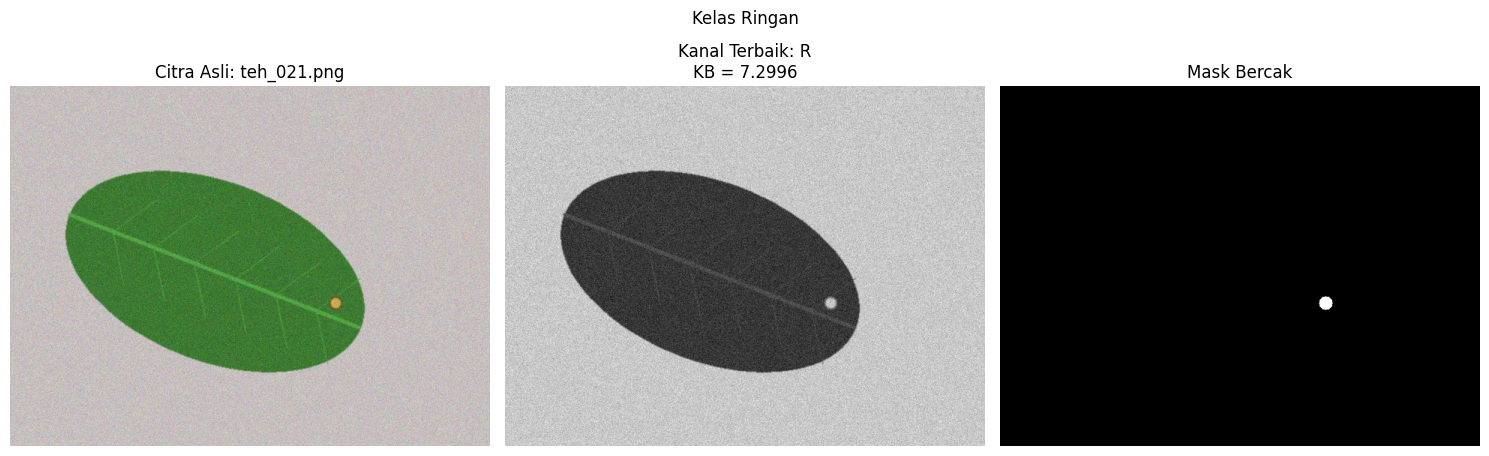

Gambar tersimpan: /content/drive/MyDrive/simuteh/hasil/teh_021_kanal_terbaik.png
Kanal terbaik: R | KB: 7.2996


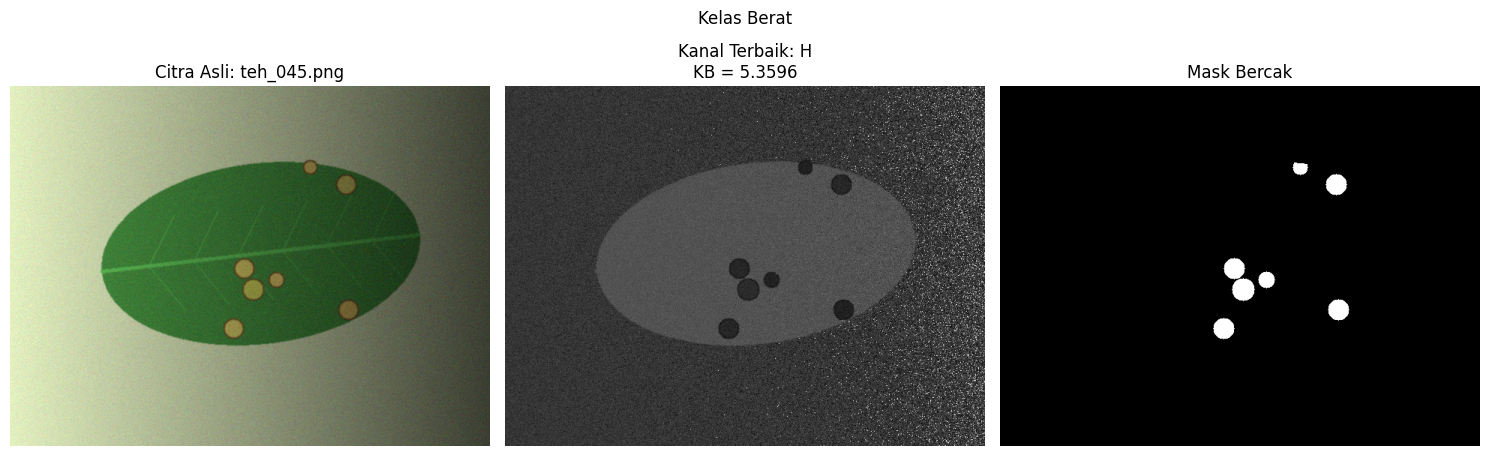

Gambar tersimpan: /content/drive/MyDrive/simuteh/hasil/teh_045_kanal_terbaik.png
Kanal terbaik: H | KB: 5.3596


In [27]:
import os
import cv2
import matplotlib.pyplot as plt
import pandas as pd

def simpan_visualisasi_kanal(nama_file, data_kb, kelas):
    # Lokasi citra dan mask
    path_citra = os.path.join(DATA_DIR, "citra", nama_file)
    path_mask = os.path.join(DATA_DIR, "mask_bercak", nama_file)

    # Baca citra
    citra = cv2.imread(path_citra)
    mask = cv2.imread(path_mask, cv2.IMREAD_GRAYSCALE)

    if citra is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path_citra}")

    if mask is None:
        raise FileNotFoundError(f"Mask tidak ditemukan: {path_mask}")

    # Cari kanal dengan KB tertinggi untuk citra ini
    baris = data_kb[data_kb["nama_file"] == nama_file]

    if baris.empty:
        raise ValueError(f"Data KB untuk {nama_file} tidak ditemukan.")

    baris_terbaik = baris.loc[baris["KB"].idxmax()]
    kanal_terbaik = baris_terbaik["kanal"]
    nilai_kb = baris_terbaik["KB"]

    # Konversi citra ke kanal yang sesuai
    citra_rgb = cv2.cvtColor(citra, cv2.COLOR_BGR2RGB)

    if kanal_terbaik in ["B", "G", "R"]:
        indeks = {"B": 0, "G": 1, "R": 2}[kanal_terbaik]
        kanal = citra[:, :, indeks]
    elif kanal_terbaik == "Grayscale":
        kanal = cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)
    elif kanal_terbaik in ["H", "S", "V"]:
        hsv = cv2.cvtColor(citra, cv2.COLOR_BGR2HSV)
        indeks = {"H": 0, "S": 1, "V": 2}[kanal_terbaik]
        kanal = hsv[:, :, indeks]
    else:
        raise ValueError(f"Kanal tidak dikenali: {kanal_terbaik}")

    # Tampilkan dan simpan panel
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))

    ax[0].imshow(citra_rgb)
    ax[0].set_title(f"Citra Asli: {nama_file}")

    ax[1].imshow(kanal, cmap="gray")
    ax[1].set_title(f"Kanal Terbaik: {kanal_terbaik}\nKB = {nilai_kb:.4f}")

    ax[2].imshow(mask, cmap="gray")
    ax[2].set_title("Mask Bercak")

    for a in ax:
        a.axis("off")

    fig.suptitle(f"Kelas {kelas.capitalize()}")
    plt.tight_layout()

    nama_output = nama_file.replace(".png", "_kanal_terbaik.png")
    path_output = os.path.join(HASIL_DIR, nama_output)

    plt.savefig(path_output, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Gambar tersimpan: {path_output}")
    print(f"Kanal terbaik: {kanal_terbaik} | KB: {nilai_kb:.4f}")


# Visualisasi kelas ringan
simpan_visualisasi_kanal(
    "teh_021.png",
    df_kb_ringan,
    "ringan"
)

# Visualisasi kelas berat
simpan_visualisasi_kanal(
    "teh_045.png",
    df_kb_berat,
    "berat"
)